# DeBERTa v3 Multitask Retrain — Clean Version

Changes from original:
- fp16 bug fixed: `.float()` cast on hidden states before GRU
- Post-save verification: reloads checkpoint and confirms CCC matches
- Saves to `best_model_v2.pt` (doesn't overwrite the existing checkpoint)
- Optimizer state removed from save (not needed for v6.1 inference)
- Patience bumped 10→15

In [ ]:
# ── Cell 1: Install & imports ──────────────────────────────────────────────────
!pip install -q transformers==4.40.0 accelerate sentencepiece protobuf scikit-learn seaborn tqdm

import os, math, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.metrics import (
    f1_score, mean_squared_error, mean_absolute_error, r2_score,
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    AutoTokenizer, AutoModel, get_linear_schedule_with_warmup,
)

warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'PyTorch: {torch.__version__}')
import transformers
print(f'Transformers: {transformers.__version__}')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 122.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 135.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.4.1 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.40.0 which is incompatible.
Device: cuda
PyTorch: 2.10.0+cu128
Transformers: 4.40.0


In [ ]:
# ── Cell 2: Mount drive ────────────────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# ── Cell 3: Config ─────────────────────────────────────────────────────────────
MODEL_NAME   = 'microsoft/deberta-v3-base'
DATA_PATH    = '/content/drive/Shareddrives/AI Capstone/Dataset/CMU-MOSEI/label_text_FULLY_PRUNED.csv'
OUTPUT_DIR   = '/content/drive/Shareddrives/AI Capstone/Text model/deberta_model'
SAVE_NAME    = 'best_model_v2.pt'   # new filename — don't overwrite the old checkpoint
os.makedirs(OUTPUT_DIR, exist_ok=True)

MAX_LEN        = 128
BATCH_SIZE     = 16
EPOCHS         = 200
LR             = 2e-5
WEIGHT_DECAY   = 0.1
WARMUP_RATIO   = 0.1
PATIENCE       = 15        # bumped from 10 — peak was at epoch 8, give more room
SEED           = 42

EMOTION_COLS   = ['happy', 'sad', 'anger', 'fear', 'disgust', 'surprise']
SENTIMENT_NORM = 3.0
EMOTION_THRESH = 0.5
W_SENTIMENT    = 0.3
W_EMOTION      = 0.7

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print(f'Config ready. Saving to: {os.path.join(OUTPUT_DIR, SAVE_NAME)}')


Config ready. Saving to: /content/drive/Shareddrives/AI Capstone/Text model/deberta_model/best_model_v2.pt


In [ ]:
# ── Cell 4: Data loading ───────────────────────────────────────────────────────
df = pd.read_csv(DATA_PATH)
df = df.dropna(subset=['text'])
df['text'] = df['text'].astype(str).str.strip()
df = df[df['text'] != ''].reset_index(drop=True)
print(f'Loaded: {df.shape}')

# Normalise labels
df['sentiment_norm'] = df['sentiment'] / SENTIMENT_NORM    # [-1, 1]
for col in EMOTION_COLS:
    df[f'{col}_norm'] = df[col] / SENTIMENT_NORM           # [0, 1]

train_df = df[df['mode'] == 'train'].reset_index(drop=True)
val_df   = df[df['mode'] == 'valid'].reset_index(drop=True)
test_df  = df[df['mode'] == 'test'].reset_index(drop=True)
print(f'Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}')


Loaded: (19953, 9)
Train: 14166  Val: 1671  Test: 4116


In [ ]:
# ── Cell 5: Dataset & DataLoader ───────────────────────────────────────────────
print(f'Loading tokenizer: {MODEL_NAME}')
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class EmotionDataset(Dataset):
    def __init__(self, df, tokenizer, max_len=MAX_LEN):
        self.texts      = df['text'].tolist()
        self.sentiments = df['sentiment_norm'].tolist()
        self.emotions   = df[[f'{c}_norm' for c in EMOTION_COLS]].values.astype(np.float32)
        self.tokenizer  = tokenizer
        self.max_len    = max_len

    def __len__(self): return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            return_tensors='pt',
            padding='max_length',
            truncation=True,
            max_length=self.max_len,
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'sentiment':      torch.tensor(self.sentiments[idx], dtype=torch.float),
            'emotions':       torch.tensor(self.emotions[idx],   dtype=torch.float),
        }

train_loader = DataLoader(EmotionDataset(train_df, tokenizer), batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(EmotionDataset(val_df,   tokenizer), batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(EmotionDataset(test_df,  tokenizer), batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)
print(f'Train: {len(train_loader)} batches  Val: {len(val_loader)}  Test: {len(test_loader)}')


Loading tokenizer: microsoft/deberta-v3-base


tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

Train: 886 batches  Val: 105  Test: 258


In [ ]:
# ── Cell 6: Model ──────────────────────────────────────────────────────────────
class MultiTaskDeBERTa(nn.Module):
    def __init__(self, model_name=MODEL_NAME, num_emotions=6, dropout=0.2):
        super().__init__()
        self.encoder     = AutoModel.from_pretrained(model_name)
        self.hidden_size = self.encoder.config.hidden_size
        self.gru         = nn.GRU(self.hidden_size, 256, batch_first=True, bidirectional=True)
        self.gru_size    = 256 * 2

        self.sentiment_head = nn.Sequential(
            nn.Linear(self.gru_size, 256), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(256, 1), nn.Tanh())

        self.emotion_head = nn.Sequential(
            nn.Linear(self.gru_size, 256), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(256, num_emotions), nn.Sigmoid())

        self._init_heads()

    def _init_heads(self):
        for module in [self.sentiment_head, self.emotion_head]:
            for layer in module:
                if isinstance(layer, nn.Linear):
                    nn.init.xavier_uniform_(layer.weight)
                    nn.init.zeros_(layer.bias)

    def forward(self, input_ids, attention_mask):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        # ── fp16 fix: DeBERTa V3 may autocast to fp16 internally on T4.
        # GRU weights are fp32, so we explicitly cast hidden states before the GRU.
        hidden = outputs.last_hidden_state.float()          # (B, L, 768) fp32
        gru_out, _ = self.gru(hidden)                       # (B, L, 512)
        pooled = torch.mean(gru_out, dim=1)                 # (B, 512)
        return (self.sentiment_head(pooled).squeeze(-1),    # (B,)
                self.emotion_head(pooled))                  # (B, 6)

print(f'Loading model: {MODEL_NAME}')
model = MultiTaskDeBERTa(MODEL_NAME).to(device)

total_p     = sum(p.numel() for p in model.parameters())
trainable_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params:     {total_p:,}')
print(f'Trainable params: {trainable_p:,}')


Loading model: microsoft/deberta-v3-base


pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

Total params:     185,671,943
Trainable params: 185,671,943


In [ ]:
# ── Cell 7: Loss function ──────────────────────────────────────────────────────
class MultiTaskLoss(nn.Module):
    def __init__(self, w_sentiment=W_SENTIMENT, w_emotion=W_EMOTION):
        super().__init__()
        self.w_sentiment = w_sentiment
        self.w_emotion   = w_emotion
        self.emotion_weights = torch.tensor(
            [1.00, 2.55, 3.20, 12.06, 4.60, 10.78], dtype=torch.float).to(device)

    def forward(self, pred_sent, pred_emot, true_sent, true_emot):
        loss_sent = torch.mean((pred_sent - true_sent)**2)
        mse_emot  = (pred_emot - true_emot)**2
        loss_emot = torch.mean(mse_emot * self.emotion_weights)
        total     = self.w_sentiment * loss_sent + self.w_emotion * loss_emot
        return total, loss_sent.item(), loss_emot.item()

criterion = MultiTaskLoss()
print('Loss: Weighted Multi-Task MSE')
print(f'  W_sentiment={W_SENTIMENT}  W_emotion={W_EMOTION}')


Loss: Weighted Multi-Task MSE
  W_sentiment=0.3  W_emotion=0.7


In [ ]:
# ── Cell 8: Metrics ────────────────────────────────────────────────────────────
def compute_ccc(y_true, y_pred):
    cor       = np.corrcoef(y_true, y_pred)[0, 1]
    sd_true   = np.std(y_true);  sd_pred  = np.std(y_pred)
    var_true  = np.var(y_true);  var_pred = np.var(y_pred)
    mean_true = np.mean(y_true); mean_pred = np.mean(y_pred)
    num = 2 * cor * sd_true * sd_pred
    den = var_true + var_pred + (mean_true - mean_pred)**2
    return float(num / den) if den > 1e-8 else 0.0

def compute_sentiment_metrics(preds, targets, norm=SENTIMENT_NORM):
    p = np.array(preds) * norm
    t = np.array(targets) * norm
    return {
        'RMSE': math.sqrt(mean_squared_error(t, p)),
        'MAE':  mean_absolute_error(t, p),
        'R2':   r2_score(t, p),
        'PLCC': float(np.corrcoef(p, t)[0, 1]),
        'CCC':  compute_ccc(t, p),
    }

def compute_emotion_metrics(preds, targets):
    preds_arr = np.array(preds); targets_arr = np.array(targets)
    res = {}
    for i, c in enumerate(EMOTION_COLS):
        p_e = preds_arr[:, i]; t_e = targets_arr[:, i]
        res[f'{c}_MSE']  = float(mean_squared_error(t_e, p_e))
        res[f'{c}_PLCC'] = float(np.corrcoef(p_e, t_e)[0, 1]) if np.std(p_e) > 0 and np.std(t_e) > 0 else 0.0
        res[f'{c}_CCC']  = compute_ccc(t_e, p_e) if np.std(p_e) > 0 and np.std(t_e) > 0 else 0.0
    bin_preds   = (preds_arr   >= EMOTION_THRESH).astype(int)
    bin_targets = (targets_arr >= EMOTION_THRESH).astype(int)
    res['F1_macro'] = f1_score(bin_targets, bin_preds, average='macro', zero_division=0)
    res['F1_micro'] = f1_score(bin_targets, bin_preds, average='micro', zero_division=0)
    for i, c in enumerate(EMOTION_COLS):
        res[f'{c}_F1'] = f1_score(bin_targets[:, i], bin_preds[:, i], zero_division=0)
    return res

def print_metrics(sent_mets, emot_mets, prefix=''):
    print(f'\n{"─"*65}')
    print(f'  {prefix}')
    print(f'{"─"*65}')
    print(f'  Sentiment: PLCC={sent_mets["PLCC"]:.4f}  CCC={sent_mets["CCC"]:.4f}  MAE={sent_mets["MAE"]:.4f}')
    print(f'  Emotions:')
    for c in EMOTION_COLS:
        print(f'    {c:<10}: PLCC={emot_mets[f"{c}_PLCC"]:.4f}  CCC={emot_mets[f"{c}_CCC"]:.4f}  F1={emot_mets[f"{c}_F1"]:.4f}')
    print(f'{"─"*65}')


In [ ]:
# ── Cell 9: Train / eval functions ─────────────────────────────────────────────
def train_one_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss = total_sent = total_emot = 0.0
    for batch in tqdm(loader, desc='  Training', leave=False):
        ids   = batch['input_ids'].to(device)
        mask  = batch['attention_mask'].to(device)
        ts    = batch['sentiment'].to(device)
        te    = batch['emotions'].to(device)
        optimizer.zero_grad()
        ps, pe = model(ids, mask)
        loss, sl, el = criterion(ps, pe, ts, te)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item(); total_sent += sl; total_emot += el
    n = len(loader)
    return total_loss/n, total_sent/n, total_emot/n


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = total_sent = total_emot = 0.0
    all_sp, all_st, all_ep, all_et = [], [], [], []
    for batch in tqdm(loader, desc='  Evaluating', leave=False):
        ids  = batch['input_ids'].to(device)
        mask = batch['attention_mask'].to(device)
        ts   = batch['sentiment'].to(device)
        te   = batch['emotions'].to(device)
        ps, pe = model(ids, mask)
        loss, sl, el = criterion(ps, pe, ts, te)
        total_loss += loss.item(); total_sent += sl; total_emot += el
        all_sp.extend(ps.cpu().numpy()); all_st.extend(ts.cpu().numpy())
        all_ep.extend(pe.cpu().numpy()); all_et.extend(te.cpu().numpy())
    n = len(loader)
    return ((total_loss/n, total_sent/n, total_emot/n),
            compute_sentiment_metrics(all_sp, all_st),
            compute_emotion_metrics(all_ep, all_et))


In [ ]:
# ── Cell 10: Optimizer + scheduler ─────────────────────────────────────────────
no_decay = ['bias', 'LayerNorm.weight']
param_groups = [
    {'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
     'weight_decay': WEIGHT_DECAY},
    {'params': [p for n, p in model.named_parameters() if     any(nd in n for nd in no_decay)],
     'weight_decay': 0.0},
]
optimizer    = AdamW(param_groups, lr=LR)
total_steps  = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
scheduler    = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

print(f'Optimizer: AdamW  lr={LR}  weight_decay={WEIGHT_DECAY}')
print(f'Total steps: {total_steps}  Warmup: {warmup_steps}')


Optimizer: AdamW  lr=2e-05  weight_decay=0.1
Total steps: 177200  Warmup: 17720


In [ ]:
# ── Cell 11: Training loop ──────────────────────────────────────────────────────
BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, SAVE_NAME)
best_val_loss   = float('inf')
best_ccc        = -1.0
history         = []
epochs_no_improve = 0

# ── Epoch 1: encoder frozen (head warmup) ────────────────────────────────────
for param in model.encoder.parameters():
    param.requires_grad = False
print('Epoch 1: encoder frozen — warming up GRU + heads')

(tr_loss, tr_s, tr_e) = train_one_epoch(model, train_loader, optimizer, scheduler, criterion, device)
(val_losses, val_sent_mets, val_emot_mets) = evaluate(model, val_loader, criterion, device)
val_loss = val_losses[0]

print(f'  [1] tr={tr_loss:.4f}  val={val_loss:.4f}  '
      f'SCCC={val_sent_mets["CCC"]:.4f}  PLCC={val_sent_mets["PLCC"]:.4f}')

history.append({'epoch': 1, 'train_loss': tr_loss, 'val_loss': val_loss,
                **{f'val_{k}': v for k, v in val_sent_mets.items()},
                **{f'val_{k}': v for k, v in val_emot_mets.items()}})

# ── Epoch 2+: encoder unfrozen ────────────────────────────────────────────────
for param in model.encoder.parameters():
    param.requires_grad = True
print('Encoder unfrozen — full model training')

for epoch in range(2, EPOCHS + 1):
    (tr_loss, tr_s, tr_e) = train_one_epoch(model, train_loader, optimizer, scheduler, criterion, device)
    (val_losses, val_sent_mets, val_emot_mets) = evaluate(model, val_loader, criterion, device)
    val_loss = val_losses[0]
    val_ccc  = val_sent_mets['CCC']

    history.append({'epoch': epoch, 'train_loss': tr_loss, 'val_loss': val_loss,
                    **{f'val_{k}': v for k, v in val_sent_mets.items()},
                    **{f'val_{k}': v for k, v in val_emot_mets.items()}})

    flag = ''
    if val_loss < best_val_loss:
        best_val_loss     = val_loss
        best_ccc          = val_ccc
        epochs_no_improve = 0
        flag = ' ✓ saved'

        # ── Save ──────────────────────────────────────────────────────────────
        torch.save({
            'epoch':            epoch,
            'model_state_dict': model.state_dict(),
            'val_loss':         val_loss,
            'val_sent_metrics': val_sent_mets,
            'val_emot_metrics': val_emot_mets,
        }, BEST_MODEL_PATH)

        # ── Post-save verification ────────────────────────────────────────────
        # Reload just-saved weights into a fresh model and check CCC matches.
        # This is the check that would have caught the previous checkpoint bug.
        saved_ckpt  = torch.load(BEST_MODEL_PATH, map_location=device, weights_only=False)
        verify_m    = MultiTaskDeBERTa(MODEL_NAME).to(device)
        verify_m.load_state_dict(saved_ckpt['model_state_dict'])
        verify_m.eval()
        v_sp, v_st = [], []
        with torch.no_grad():
            for vb in val_loader:
                ps, _ = verify_m(vb['input_ids'].to(device), vb['attention_mask'].to(device))
                v_sp.extend(ps.cpu().numpy()); v_st.extend(vb['sentiment'].numpy())
        verify_ccc = compute_ccc(np.array(v_st), np.array(v_sp))
        ccc_match  = abs(verify_ccc - val_ccc) < 0.01
        flag += f'  verify_CCC={verify_ccc:.4f} {"✓" if ccc_match else "✗ MISMATCH"}'
        del verify_m

    else:
        epochs_no_improve += 1

    print(f'  [{epoch:>3}] tr={tr_loss:.4f}  val={val_loss:.4f}  '
          f'SCCC={val_ccc:.4f}  PLCC={val_sent_mets["PLCC"]:.4f}  '
          f'patience={epochs_no_improve}{flag}')

    if epochs_no_improve >= PATIENCE:
        print(f'\nEarly stop @ epoch {epoch}  |  best val_loss={best_val_loss:.4f}  best_SCCC={best_ccc:.4f}')
        break

# Save training history
hist_df = pd.DataFrame(history)
hist_df.to_csv(os.path.join(OUTPUT_DIR, 'training_history_v2.csv'), index=False)
print(f'\nTraining complete. Checkpoint: {BEST_MODEL_PATH}')


Epoch 1: encoder frozen — warming up GRU + heads


  [1] tr=0.7279  val=0.1340  SCCC=0.0006  PLCC=0.0025
Encoder unfrozen — full model training


  [  2] tr=0.0850  val=0.0550  SCCC=0.3808  PLCC=0.4798  patience=0 ✓ saved  verify_CCC=0.3808 ✓


  [  3] tr=0.0624  val=0.0485  SCCC=0.5154  PLCC=0.6005  patience=0 ✓ saved  verify_CCC=0.5154 ✓


  [  4] tr=0.0563  val=0.0455  SCCC=0.6172  PLCC=0.6478  patience=0 ✓ saved  verify_CCC=0.6172 ✓


  [  5] tr=0.0514  val=0.0453  SCCC=0.6656  PLCC=0.6769  patience=0 ✓ saved  verify_CCC=0.6656 ✓


... (14 outputs left out)

  [ 20] tr=0.0238  val=0.0432  SCCC=0.6576  PLCC=0.6649  patience=12


  [ 21] tr=0.0227  val=0.0440  SCCC=0.6640  PLCC=0.6709  patience=13


  [ 22] tr=0.0218  val=0.0447  SCCC=0.6615  PLCC=0.6633  patience=14


  [ 23] tr=0.0208  val=0.0464  SCCC=0.6627  PLCC=0.6652  patience=15

Early stop @ epoch 23  |  best val_loss=0.0424  best_SCCC=0.6727

Training complete. Checkpoint: /content/drive/Shareddrives/AI Capstone/Text model/deberta_model/best_model_v2.pt


In [ ]:
# ── Cell 12: Test evaluation ────────────────────────────────────────────────────
print(f'Loading best model: {BEST_MODEL_PATH}')
ckpt = torch.load(BEST_MODEL_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
print(f'  Epoch {ckpt["epoch"]}  val_loss={ckpt["val_loss"]:.4f}  '
      f'val_CCC={ckpt["val_sent_metrics"]["CCC"]:.4f}')

(test_losses, test_sent_mets, test_emot_mets) = evaluate(model, test_loader, criterion, device)
print(f'\nTest loss: {test_losses[0]:.4f}')
print_metrics(test_sent_mets, test_emot_mets, prefix='FINAL TEST RESULTS')


Loading best model: /content/drive/Shareddrives/AI Capstone/Text model/deberta_model/best_model_v2.pt
  Epoch 8  val_loss=0.0424  val_CCC=0.6727



Test loss: 0.0462

─────────────────────────────────────────────────────────────────
  FINAL TEST RESULTS
─────────────────────────────────────────────────────────────────
  Sentiment: PLCC=0.6994  CCC=0.6917  MAE=0.5962
  Emotions:
    happy     : PLCC=0.3971  CCC=0.2587  F1=0.0056
    sad       : PLCC=0.2099  CCC=0.0867  F1=0.0000
    anger     : PLCC=0.3335  CCC=0.1871  F1=0.0000
    fear      : PLCC=0.1013  CCC=0.0182  F1=0.0000
    disgust   : PLCC=0.5028  CCC=0.4099  F1=0.0465
    surprise  : PLCC=0.0353  CCC=0.0029  F1=0.0000
─────────────────────────────────────────────────────────────────


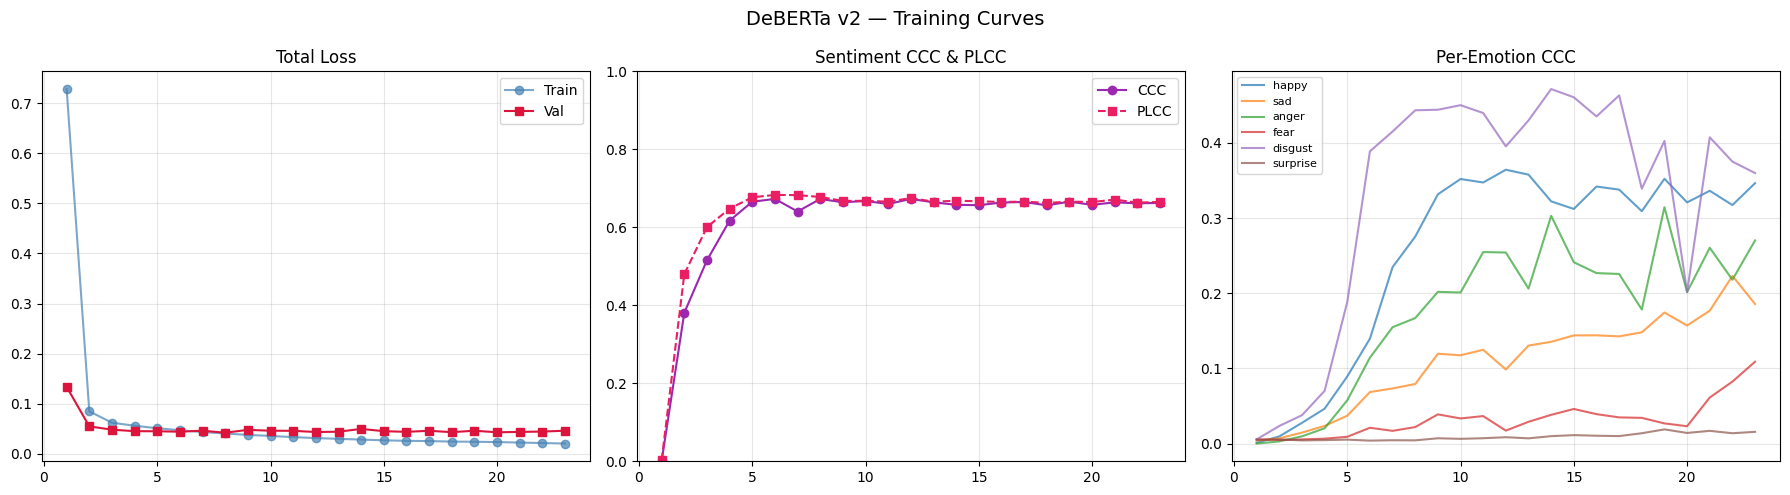

In [ ]:
# ── Cell 13: Training curves ────────────────────────────────────────────────────
hist_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(hist_df['epoch'], hist_df['train_loss'], 'o-', label='Train', color='steelblue', alpha=0.7)
axes[0].plot(hist_df['epoch'], hist_df['val_loss'],   's-', label='Val',   color='crimson')
axes[0].set_title('Total Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(hist_df['epoch'], hist_df['val_CCC'],  'o-', color='#9C27B0', label='CCC')
axes[1].plot(hist_df['epoch'], hist_df['val_PLCC'], 's-', color='#E91E63', label='PLCC', linestyle='--')
axes[1].set_title('Sentiment CCC & PLCC'); axes[1].set_ylim(0, 1)
axes[1].legend(); axes[1].grid(alpha=0.3)

emot_ccc_cols = [f'val_{c}_CCC' for c in EMOTION_COLS]
for col, c in zip(emot_ccc_cols, EMOTION_COLS):
    if col in hist_df.columns:
        axes[2].plot(hist_df['epoch'], hist_df[col], label=c, alpha=0.7)
axes[2].set_title('Per-Emotion CCC'); axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)

plt.suptitle('DeBERTa v2 — Training Curves', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'training_curves_v2.png'), dpi=150, bbox_inches='tight')
plt.show()
